# M1: Basic structure of the U.S. Flight Network

**Paper section covered:** 3 (Nodes and Edges, Average Shortest Path Length, Network Diameter, Degree Distribution, Betweenness Centrality)

## Goal
Reproduce the paper's first set of structural results on the exact network built in M0, and understand *why* the numbers come out as they do.

## What the paper reports
| Quantity | Paper |
|---|---|
| Average shortest path length L (Eq. 1) | 3.2 |
| Diameter | 7 |
| Average degree | 10 |
| Highest degree | 153, airport ATL |
| Degree distribution | Fig. 1 (heavy tail) |
| Betweenness distribution | Fig. 2 (cumulative, log-log) |
| Highest betweenness | ANC (Anchorage) |

## What this notebook adds
- Which edge definition the paper's betweenness really uses (weighted or not), settled by testing.
- The full distribution of path lengths, and *who* sits at the diameter.
- How concentrated the network is in its hubs, and the hub-and-spoke signature (degree disassortativity).
- A concrete explanation of why Anchorage beats Atlanta on betweenness.

## 1. Setup

In [1]:
import sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREY = "#3b6ea5", "#c05746", "#777777"

airports, routes = usfn.load_openflights()
G = usfn.build_country_network(airports, routes)          # the 541-node network from M0
N, M = G.number_of_nodes(), G.number_of_edges()
assert (N, M) == (541, 2780)
print(f"USFN loaded: {N} nodes, {M} edges")

USFN loaded: 541 nodes, 2780 edges


## 2. Global statistics at a glance

Everything the paper states in Section 3, plus a few standard measures it does not.

In [2]:
deg = dict(G.degree())
sp = dict(nx.all_pairs_shortest_path_length(G))                         # BFS from every node (unweighted hops)

# Eq. (1): L = 1/(n(n-1)) * sum_{i != j} d_ij   (computed directly, not via networkx)
L_eq1 = sum(d for u in sp for v, d in sp[u].items() if u != v) / (N * (N - 1))
L_nx = nx.average_shortest_path_length(G)
diam = max(max(d.values()) for d in sp.values())

stats = pd.DataFrame([
    ("Nodes",                             541,   N),
    ("Edges",                             2780,  M),
    ("Average degree  (2M/N)",            10,    round(2 * M / N, 2)),
    ("Highest degree",                    153,   max(deg.values())),
    ("Average shortest path length (Eq.1)", 3.2, round(L_eq1, 4)),
    ("  same, via networkx",              3.2,   round(L_nx, 4)),
    ("Diameter",                          7,     diam),
    ("Average clustering coefficient",    0.49,  round(nx.average_clustering(G), 4)),
    ("Density",                           None,  round(nx.density(G), 4)),
    ("Transitivity (global clustering)",  None,  round(nx.transitivity(G), 4)),
    ("Degree assortativity",              None,  round(nx.degree_assortativity_coefficient(G), 4)),
    ("Median degree",                     None,  float(np.median(list(deg.values())))),
], columns=["quantity", "paper", "ours"])
stats.style.hide(axis="index").format(precision=4, na_rep="not reported")

quantity,paper,ours
Nodes,541.0000,541.0000
Edges,2780.0000,2780.0000
Average degree (2M/N),10.0000,10.2800
Highest degree,153.0000,153.0000
Average shortest path length (Eq.1),3.2000,3.2000
"same, via networkx",3.2000,3.2000
Diameter,7.0000,7.0000
Average clustering coefficient,0.4900,0.4944
Density,not reported,0.0190
Transitivity (global clustering),not reported,0.3127


Our Eq. (1) value and networkx agree to all printed digits, so the formula in the paper is exactly what is being computed (unweighted hop counts; the weights play no role). The paper reports the *average local* clustering coefficient (0.49); the *global* version (transitivity) is lower, 0.31, because low-degree airports whose few neighbours are all linked pull the local average up.

## 3. Path lengths and the diameter (paper 3.2 and 3.3)

The paper gives one number for each. The distribution behind them is more informative: how many of the 146,070 airport pairs are 1, 2, ..., 7 hops apart?

,pairs,share,cumulative
hops,,,
1,2780,0.0190,0.0190
2,36345,0.2488,0.2679
3,53030,0.3630,0.6309
4,38324,0.2624,0.8933
5,14025,0.0960,0.9893
6,1512,0.0104,0.9996
7,54,0.0004,1.0000


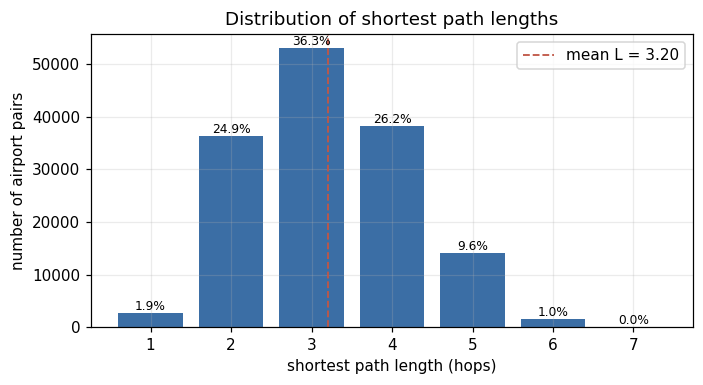

In [3]:
dist_counts = Counter(d for u in sp for v, d in sp[u].items() if u < v)      # each unordered pair once
dc = pd.Series(dist_counts).sort_index()
assert dc.sum() == N * (N - 1) // 2

tbl = pd.DataFrame({"pairs": dc, "share": (dc / dc.sum()).round(4), "cumulative": (dc.cumsum() / dc.sum()).round(4)})
tbl.index.name = "hops"
display(tbl)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(dc.index, dc.values, color=BLUE)
for h, c in dc.items():
    ax.text(h, c, f"{c / dc.sum():.1%}", ha="center", va="bottom", fontsize=8)
ax.axvline(L_eq1, color=RED, ls="--", lw=1.2, label=f"mean L = {L_eq1:.2f}")
ax.set_xlabel("shortest path length (hops)"); ax.set_ylabel("number of airport pairs")
ax.set_title("Distribution of shortest path lengths"); ax.legend()
plt.tight_layout(); plt.show()

In [4]:
ecc = nx.eccentricity(G)
at_diam = [n for n, e in ecc.items() if e == diam]
pairs_diam = [(u, v) for u in sp for v, d in sp[u].items() if d == diam and u < v]
ak = {n for n in G if G.nodes[n]["lat"] > 50}                     # Alaska: nothing else in the data lies north of 50 N

print(f"Diameter = {diam}: only {len(pairs_diam)} of {N*(N-1)//2:,} airport pairs are that far apart.")
print(f"{len(at_diam)} airports have eccentricity {diam}; {sum(n in ak for n in at_diam)} of them are in Alaska.")
print(f"Radius = {nx.radius(G)}; center airports (eccentricity {nx.radius(G)}): {sorted(nx.center(G))}")

u, v = pairs_diam[0]
path = nx.shortest_path(G, u, v)
print("\nExample longest shortest path:", " -> ".join(path), f"({len(path)-1} flights, {len(path)-2} intermediate stops)")
print("\nEccentricity distribution:", dict(sorted(Counter(ecc.values()).items())))

Diameter = 7: only 54 of 146,070 airport pairs are that far apart.
31 airports have eccentricity 7; 5 of them are in Alaska.


Radius = 4; center airports (eccentricity 4): ['ANC', 'FAI', 'SEA']

Example longest shortest path: KYK -> KLN -> ADQ -> ANC -> ORD -> ATL -> TTN -> UST (7 flights, 6 intermediate stops)

Eccentricity distribution: {4: 3, 5: 109, 6: 398, 7: 31}


**Reading this.**
- The typical pair is **3 hops** apart and 89% of pairs are within 4 hops: a small-world network, built around hubs.
- The diameter (7) is an extreme, not a typical value: only 54 of 146,070 pairs reach it. **50 of those 54 pairs join a remote Alaskan airport to a small lower-48 airport**, and Arctic Village (ARC) alone is an endpoint of 30 of them. The lower-48 endpoints are spokes with only 1 or 2 connections (19 of the 31 airports with eccentricity 7 have a single connection), so a journey must go spoke -> hub -> ... -> ANC -> a chain of Alaskan hops.
- The network's **center** (smallest eccentricity, 4) is ANC, FAI and SEA, not ATL: the farthest points of the network are in Alaska, so the airports that sit best between Alaska and the lower 48 are the most central in the distance sense.
- Wording note: the paper says a diameter of 7 means "at most 7 stops". Precisely, it is **7 flights**, i.e. 6 intermediate stops (see the example path above).

## 4. Degree distribution (paper 3.4, Fig. 1)

The paper shows P(k), the fraction of airports with degree k, on linear axes. We reproduce that and add the log-log view that M2 will need for the power-law analysis.

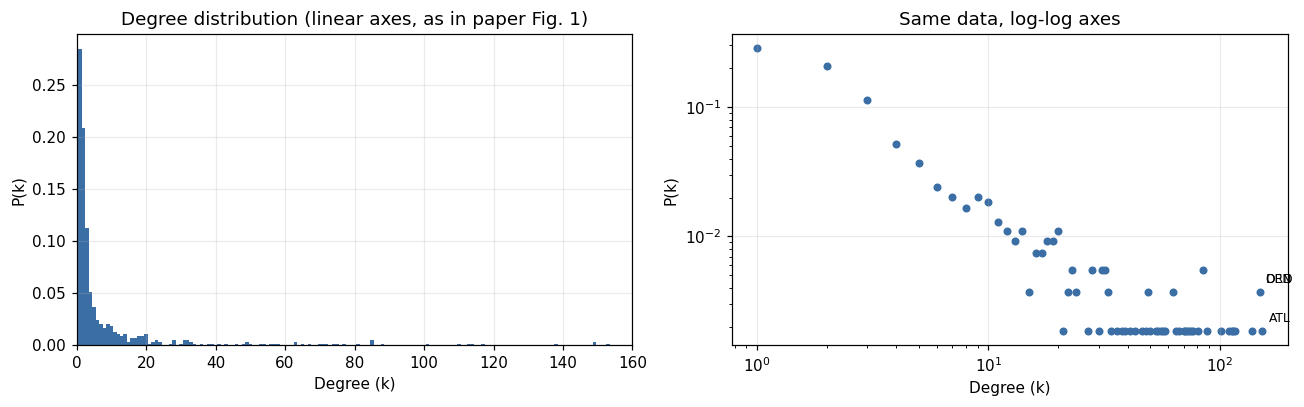

Degree 1: 28.5% of airports | degree <= 5: 69.5% | median degree: 3 | mean: 10.28
Top 10 airports (1.8% of nodes) hold 22.2% of all edge endpoints
Top 5% of airports (27) hold 43.8% of all edge endpoints


In [5]:
ks = np.array(sorted(set(deg.values())))
cnt = Counter(deg.values())
pk = np.array([cnt[k] for k in ks]) / N

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(ks, pk, width=1.0, color=BLUE)
axes[0].set_xlabel("Degree (k)"); axes[0].set_ylabel("P(k)"); axes[0].set_xlim(0, 160)
axes[0].set_title("Degree distribution (linear axes, as in paper Fig. 1)")

axes[1].scatter(ks, pk, s=18, color=BLUE)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("Degree (k)"); axes[1].set_ylabel("P(k)")
axes[1].set_title("Same data, log-log axes")
for n, d in sorted(G.degree, key=lambda x: -x[1])[:3]:
    axes[1].annotate(n, (d, cnt[d] / N), xytext=(4, 6), textcoords="offset points", fontsize=8)
plt.tight_layout(); plt.show()

dseq = np.sort(np.array(list(deg.values())))[::-1]
print(f"Degree 1: {cnt[1]/N:.1%} of airports | degree <= 5: {(dseq <= 5).mean():.1%} | median degree: {np.median(dseq):.0f} | mean: {dseq.mean():.2f}")
print(f"Top 10 airports (1.8% of nodes) hold {dseq[:10].sum() / dseq.sum():.1%} of all edge endpoints")
print(f"Top 5% of airports ({int(0.05*N)}) hold {dseq[:int(0.05*N)].sum() / dseq.sum():.1%} of all edge endpoints")

In [6]:
top = pd.Series(deg).sort_values(ascending=False, kind="stable").head(10)
b_rank = pd.Series(nx.betweenness_centrality(G)).rank(ascending=False, method="min")
t = pd.DataFrame({"airport": top.index, "city": [G.nodes[n]["city"] for n in top.index], "degree": top.values,
                  "betweenness rank": [int(b_rank[n]) for n in top.index]})
t.index = np.arange(1, 11); t

,airport,city,degree,betweenness rank
1,ATL,Atlanta,153,5
2,ORD,Chicago,149,3
3,DEN,Denver,149,2
4,DFW,Dallas-Fort Worth,138,7
5,MSP,Minneapolis,117,6
6,DTW,Detroit,114,18
7,LAS,Las Vegas,113,10
8,CLT,Charlotte,110,14
9,IAH,Houston,101,21
10,PHL,Philadelphia,88,25


**Reading this.**
- Most airports are tiny: **28% have a single connection**, 70% have 5 or fewer, and the median is 3, while the mean (10.3) is pulled up by a few hubs.
- The very top is a short list: ATL (153), ORD and DEN (149 each), DFW (138), MSP (117). Ten airports (under 2% of the nodes) account for 22% of all edge endpoints, and the top 5% (27 airports) for 44%.
- ORD and DEN tie at 149, so their order depends on tie-breaking; this matters when comparing with the paper's Table 4 later.
- The "betweenness rank" column already hints at the next section: ATL is the top airport by degree but not by betweenness.

## 5. Betweenness centrality (paper 3.5, Fig. 2)

### Which definition does the paper use?
The paper writes the graph as G = (V, E, W) with weights, but gives betweenness as a sum over shortest paths with no weights in the formula. Three readings are possible, so we test all of them against the paper's two stated facts: **ANC is the top airport**, and Table 4's betweenness top 5 is **ANC, DEN, ORD, SEA, ATL**.

In [7]:
H = G.copy()
for u, v, d in H.edges(data=True):
    d["inv_w"] = 1.0 / d["weight"]          # heavier edge = "shorter" (more service = closer)

bc = pd.Series(nx.betweenness_centrality(G))                                   # unweighted hops (normalised)
bc_inv = pd.Series(nx.betweenness_centrality(H, weight="inv_w"))               # weighted, distance = 1/weight
bc_w = pd.Series(nx.betweenness_centrality(H, weight="weight"))                # weighted, distance = weight (heavier = farther)

paper_top5 = ["ANC", "DEN", "ORD", "SEA", "ATL"]
variants = {"Unweighted (hops)": bc, "Weighted, distance = 1/weight": bc_inv, "Weighted, distance = weight": bc_w}
rows = []
for name, s in variants.items():
    top5 = list(s.sort_values(ascending=False).head(5).index)
    rows.append({"definition": name, "top 5": ", ".join(top5), "top = ANC": top5[0] == "ANC", "matches paper Table 4": top5 == paper_top5})
pd.DataFrame(rows)

,definition,top 5,top = ANC,matches paper Table 4
0,Unweighted (hops),"ANC, DEN, ORD, SEA, ATL",True,True
1,"Weighted, distance = 1/weight","ATL, ANC, SEA, DEN, LAX",False,False
2,"Weighted, distance = weight","ANC, DEN, MSP, SEA, SLC",True,False


Only the **unweighted** version reproduces the paper (ANC first, and the exact list ANC, DEN, ORD, SEA, ATL). So although the paper builds a weighted graph, its betweenness, like its path lengths, is computed on hop counts. This confirms that the weights are unused throughout Section 3. Using 1/weight as the distance puts ATL first, and using the weight itself as the distance keeps ANC first but swaps ORD and ATL out of the top 5 (MSP and SLC come in). So the conclusion *would* change under a weighted analysis; M7 will explore that properly.

### Reproducing Fig. 2
The paper plots the cumulative distribution of (normalised) betweenness on log-log axes. Airports with zero betweenness cannot appear on a log axis, so we count them separately.

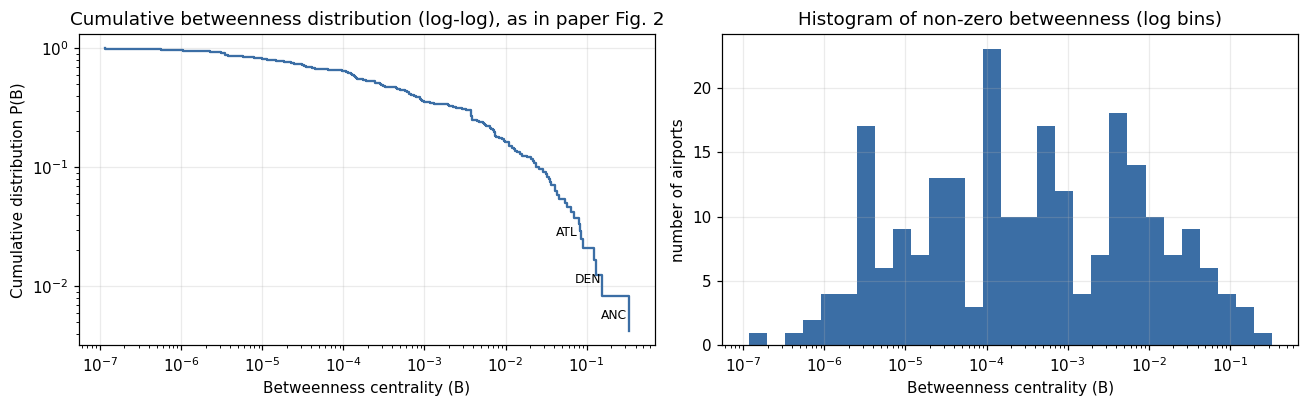

302 of 541 airports (56%) have betweenness exactly 0: no shortest path passes through them (spoke airports).
Non-zero range: 1.16e-07 to 0.329  (paper's x-axis starts near 1e-7)
Share of airports with B > 0.01: 38 (7.0%)


In [8]:
zeros = int((bc == 0).sum())
bnz = np.sort(bc[bc > 0].values)
ccdf = 1.0 - np.arange(len(bnz)) / len(bnz)                 # P(B >= x) among airports with B > 0

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].loglog(bnz, ccdf, drawstyle="steps-post", color=BLUE)
axes[0].set_xlabel("Betweenness centrality (B)"); axes[0].set_ylabel("Cumulative distribution P(B)")
axes[0].set_title("Cumulative betweenness distribution (log-log), as in paper Fig. 2")
for n in ["ANC", "DEN", "ATL"]:
    axes[0].annotate(n, (bc[n], (bnz >= bc[n]).mean()), xytext=(-18, 8), textcoords="offset points", fontsize=8)

axes[1].hist(bc[bc > 0], bins=np.logspace(np.log10(bnz.min()), np.log10(bnz.max()), 30), color=BLUE)
axes[1].set_xscale("log"); axes[1].set_xlabel("Betweenness centrality (B)"); axes[1].set_ylabel("number of airports")
axes[1].set_title("Histogram of non-zero betweenness (log bins)")
plt.tight_layout(); plt.show()

print(f"{zeros} of {N} airports ({zeros/N:.0%}) have betweenness exactly 0: no shortest path passes through them (spoke airports).")
print(f"Non-zero range: {bnz.min():.2e} to {bnz.max():.3f}  (paper's x-axis starts near 1e-7)")
print(f"Share of airports with B > 0.01: {(bc > 0.01).sum()} ({(bc > 0.01).mean():.1%})")

In [9]:
top_b = bc.sort_values(ascending=False).head(10)
tb = pd.DataFrame({"airport": top_b.index, "city": [G.nodes[n]["city"] for n in top_b.index],
                   "betweenness": top_b.values.round(4), "degree": [deg[n] for n in top_b.index],
                   "degree rank": [int(pd.Series(deg).rank(ascending=False, method="min")[n]) for n in top_b.index],
                   "state": ["Alaska" if n in ak else "" for n in top_b.index]})
tb.index = np.arange(1, 11); tb

,airport,city,betweenness,degree,degree rank,state
1,ANC,Anchorage,0.3292,34,40,Alaska
2,DEN,Denver,0.1564,149,2,
3,ORD,Chicago,0.1291,149,2,
4,SEA,Seattle,0.1248,75,16,
5,ATL,Atlanta,0.0909,153,1,
6,MSP,Minneapolis,0.0852,117,5,
7,DFW,Dallas-Fort Worth,0.0821,138,4,
8,BET,Bethel,0.0796,22,59,Alaska
9,FAI,Fairbanks,0.0702,18,73,Alaska
10,LAS,Las Vegas,0.0636,113,7,


## 6. Why is Anchorage the top betweenness airport?

ANC has far fewer connections than ATL, yet carries more shortest paths. The explanation is geography: Alaska is a large cluster of small airports with very few links to the rest of the country, and most of those links go through Anchorage.

In [10]:
ak_edges = [(u, v) for u, v in G.edges() if (u in ak) != (v in ak)]                       # Alaska <-> rest
ak_gate = Counter(u if u in ak else v for u, v in ak_edges)
print(f"Alaska airports: {len(ak)} ({len(ak)/N:.0%} of the network) | edges inside Alaska: {G.subgraph(ak).number_of_edges()} | edges to the rest of the US: {len(ak_edges)}")
print("Alaskan airports with a direct link to the lower 48 / Hawaii:", dict(ak_gate.most_common()))

Hr = G.copy(); Hr.remove_node("ANC")
main = max(nx.connected_components(Hr), key=len)
cut_off = sorted(set(G) - main - {"ANC"})
print(f"\nRemoving ANC alone disconnects {len(cut_off)} airports; all in Alaska: {all(n in ak for n in cut_off)}")
print(f"Alaskan airports that survive without ANC: {sorted(ak & main)}")
print(f"\nANC degree {deg['ANC']} vs ATL degree {deg['ATL']}, but betweenness {bc['ANC']:.3f} vs {bc['ATL']:.3f}")

Alaska airports: 131 (24% of the network) | edges inside Alaska: 192 | edges to the rest of the US: 13
Alaskan airports with a direct link to the lower 48 / Hawaii: {'ANC': 10, 'KTN': 1, 'FAI': 1, 'JNU': 1}

Removing ANC alone disconnects 87 airports; all in Alaska: True
Alaskan airports that survive without ANC: ['AET', 'AGN', 'AIN', 'AKP', 'ARC', 'ATK', 'BRW', 'BTI', 'BTT', 'CDV', 'CEM', 'CIK', 'ELV', 'FAI', 'FYU', 'GAL', 'GST', 'HNH', 'HNS', 'HSL', 'HUS', 'HYG', 'IRC', 'JNU', 'KAL', 'KLW', 'KTN', 'KYU', 'LMA', 'MLY', 'MTM', 'NUI', 'NUL', 'PIZ', 'PSG', 'RBY', 'SCC', 'SGY', 'SIT', 'VEE', 'WBQ', 'WRG', 'YAK']

ANC degree 34 vs ATL degree 153, but betweenness 0.329 vs 0.091


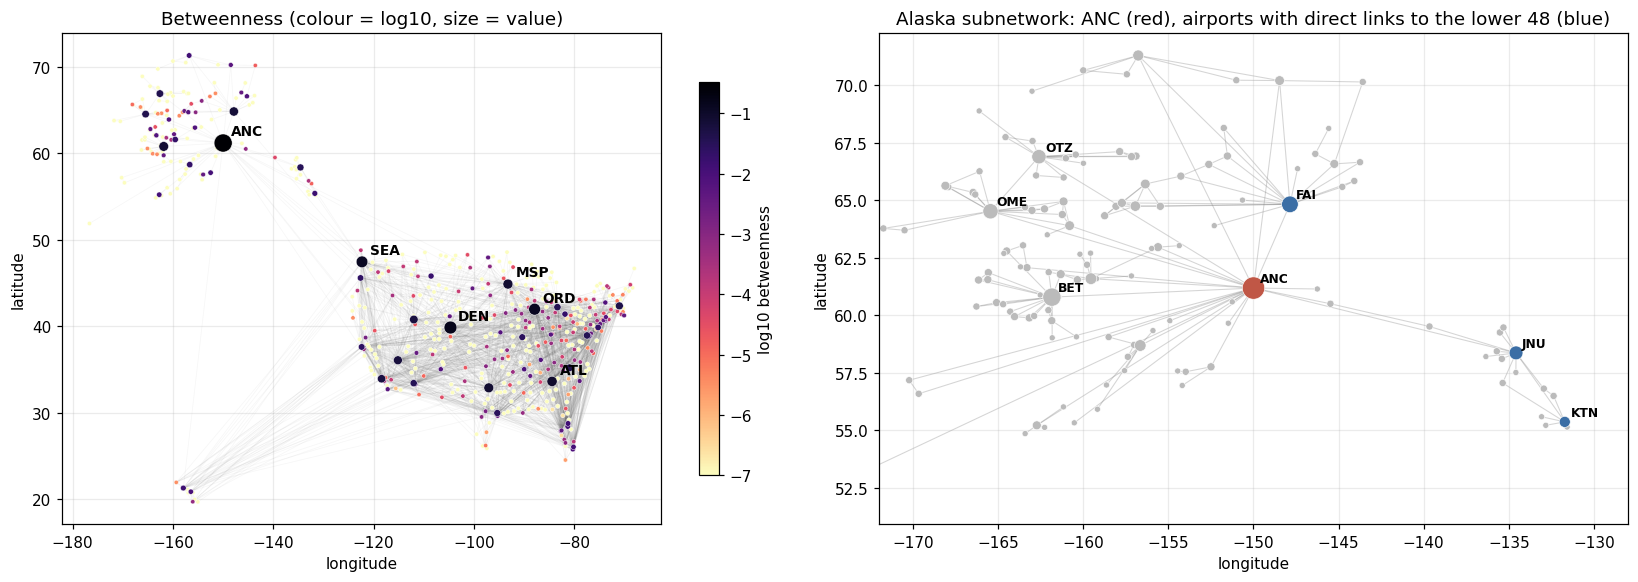

In [11]:
pos = {n: (G.nodes[n]["lon"], G.nodes[n]["lat"]) for n in G}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))

# left: whole network coloured by betweenness
ax = axes[0]
for u, v in G.edges():
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#555", alpha=0.05, lw=0.5, zorder=1)
order = sorted(G.nodes, key=lambda n: bc[n])
sc = ax.scatter([pos[n][0] for n in order], [pos[n][1] for n in order], s=[8 + 400 * bc[n] for n in order],
                c=[np.log10(bc[n] + 1e-7) for n in order], cmap="magma_r", edgecolor="white", linewidth=0.3, zorder=2)
for n in bc.sort_values(ascending=False).index[:6]:
    ax.annotate(n, pos[n], xytext=(5, 5), textcoords="offset points", fontsize=9, weight="bold")
ax.set_title("Betweenness (colour = log10, size = value)"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
plt.colorbar(sc, ax=ax, label="log10 betweenness", shrink=0.8)

# right: Alaska and its gateways
ax = axes[1]
sub = G.subgraph(ak)
for u, v in sub.edges():
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#888", alpha=0.35, lw=0.7, zorder=1)
ax.scatter([pos[n][0] for n in sub], [pos[n][1] for n in sub], s=[10 + 6 * deg[n] for n in sub],
           c=[RED if n == "ANC" else (BLUE if n in ak_gate else "#bbbbbb") for n in sub], edgecolor="white", linewidth=0.4, zorder=2)
for n in sub:
    if n == "ANC" or n in ak_gate or deg[n] >= 12:
        ax.annotate(n, pos[n], xytext=(4, 4), textcoords="offset points", fontsize=8, weight="bold")
ax.set_title("Alaska subnetwork: ANC (red), airports with direct links to the lower 48 (blue)")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_xlim(-172, -128)
plt.tight_layout(); plt.show()

**Reading this.** Alaska holds about one in four airports in the network (131 of 541) but is attached to the rest of the country by only **13 edges out of 2,780**, and **10 of those 13 end at ANC** (the others are single links from FAI, JNU and KTN). Every shortest path between an Alaskan airport and any airport elsewhere has to pass through one of these gateways, and ANC is by far the main one. This is a *bridge* position, which is exactly what betweenness measures and degree does not. It also previews the attack results of M5: removing ANC cuts off dozens of airports in a single step.

## 7. Hub-and-spoke signature: degree versus betweenness and degree correlations

Two further checks on the structure that the paper describes in words ("hub and spoke") but does not measure:
1. Is degree a good predictor of betweenness? (If not, degree-based and betweenness-based attacks will differ, as the paper later finds.)
2. Do hubs link to other hubs, or to small airports? (Degree assortativity and average neighbour degree.)

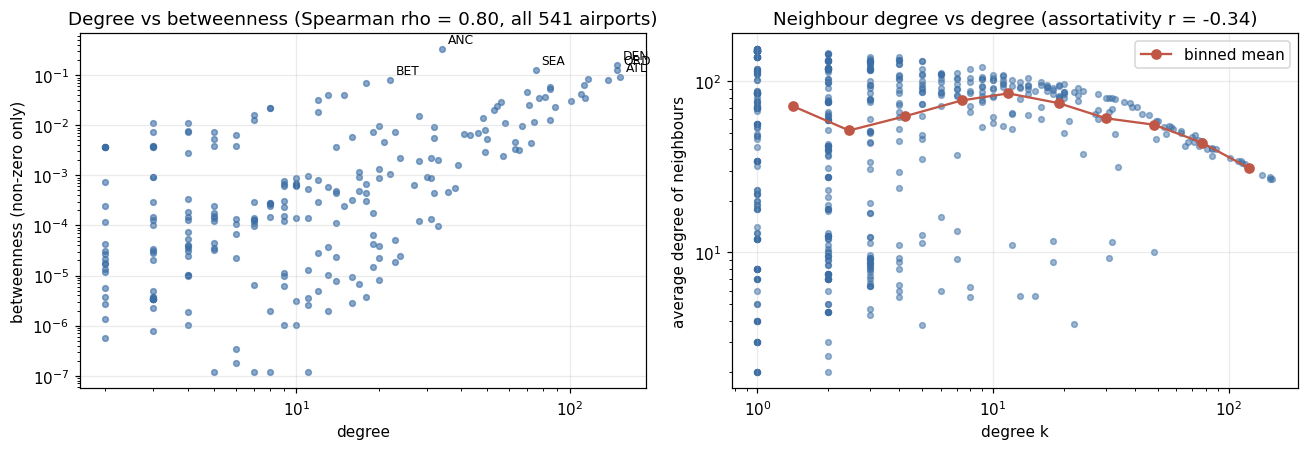

Spearman(degree, betweenness) = 0.80
Airports with degree >= 50 that are in the betweenness top 20: 14 of 20


In [12]:
d_arr = np.array([deg[n] for n in G]); b_arr = np.array([bc[n] for n in G])
rho_db = spearmanr(d_arr, b_arr).statistic
knn = nx.average_neighbor_degree(G)
kk = np.array([knn[n] for n in G])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
m = b_arr > 0
ax.scatter(d_arr[m], b_arr[m], s=14, alpha=0.6, color=BLUE)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("degree"); ax.set_ylabel("betweenness (non-zero only)")
for n in ["ANC", "ATL", "DEN", "ORD", "SEA", "BET"]:
    ax.annotate(n, (deg[n], bc[n]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_title(f"Degree vs betweenness (Spearman rho = {rho_db:.2f}, all {N} airports)")

ax = axes[1]
ax.scatter(d_arr, kk, s=14, alpha=0.5, color=BLUE)
bins = np.unique(np.logspace(0, np.log10(d_arr.max() + 1), 12).astype(int))
mean_knn = [kk[(d_arr >= lo) & (d_arr < hi)].mean() for lo, hi in zip(bins[:-1], bins[1:])]
mid = [np.sqrt(lo * hi) for lo, hi in zip(bins[:-1], bins[1:])]
ax.plot(mid, mean_knn, color=RED, marker="o", label="binned mean")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("degree k"); ax.set_ylabel("average degree of neighbours")
ax.set_title(f"Neighbour degree vs degree (assortativity r = {nx.degree_assortativity_coefficient(G):.2f})"); ax.legend()
plt.tight_layout(); plt.show()

print(f"Spearman(degree, betweenness) = {rho_db:.2f}")
print(f"Airports with degree >= 50 that are in the betweenness top 20: {sum(1 for n in bc.sort_values(ascending=False).index[:20] if deg[n] >= 50)} of 20")

**Reading this.**
- Degree and betweenness are strongly rank-correlated (Spearman 0.80), and 14 of the 20 highest-betweenness airports have degree 50 or more. But the *top* of the two rankings differs, because the other 6 are gateways with modest degree (ANC at 34, BET at 22, FAI at 18 are all in Alaska), which is why degree-based and betweenness-based attacks will differ in M5.
- The degree correlation is clearly **negative (r about -0.34)**: the average neighbour of a small airport is a big hub, while hubs, which have many small-airport neighbours, see a lower average. This is the quantitative form of "hub-and-spoke": small airports attach to hubs, not to each other. It is the opposite of what a social network (positive assortativity) looks like.

## 8. Check against the paper

Assertions comparing our results with every Section 3 claim. The degree top 5 is compared as a set plus its leader, because ORD and DEN tie at degree 149.

In [13]:
deg_top5_paper = {"ATL", "ORD", "DEN", "DFW", "MSP"}          # paper Table 4, degree column
btw_top5_paper = ["ANC", "DEN", "ORD", "SEA", "ATL"]          # paper Table 4, betweenness column

deg_top5 = list(pd.Series(deg).sort_values(ascending=False, kind="stable").head(5).index)
btw_top5 = list(bc.sort_values(ascending=False).head(5).index)

check = pd.DataFrame([
    ("Average shortest path length",   3.2,  round(L_eq1, 1)),
    ("Diameter",                       7,    diam),
    ("Average degree (rounded)",       10,   round(2 * M / N)),
    ("Highest-degree airport",         "ATL", deg_top5[0]),
    ("Highest degree",                 153,  max(deg.values())),
    ("Degree top 5 (as a set)",        sorted(deg_top5_paper), sorted(deg_top5)),
    ("Highest-betweenness airport",    "ANC", btw_top5[0]),
    ("Betweenness top 5 (in order)",   btw_top5_paper, btw_top5),
    ("Clustering (2 decimals)",        0.49, round(nx.average_clustering(G), 2)),
], columns=["quantity", "paper", "ours"])
check["match"] = ["OK" if a == b else "DIFF" for a, b in zip(check.paper, check.ours)]
display(check)

assert round(L_eq1, 1) == 3.2 and abs(L_eq1 - L_nx) < 1e-9
assert diam == 7
assert round(2 * M / N) == 10 and max(deg.values()) == 153 and deg["ATL"] == 153
assert set(deg_top5) == deg_top5_paper and deg_top5[0] == "ATL"
assert btw_top5 == btw_top5_paper
assert round(nx.average_clustering(G), 2) == 0.49
assert (bc.sort_values(ascending=False).index[0] == "ANC") and not rows[1]["matches paper Table 4"] and rows[0]["matches paper Table 4"]
assert len(cut_off) == 87 and all(n in ak for n in cut_off)
print("All M1 assertions passed.")

,quantity,paper,ours,match
0,Average shortest path length,3.2,3.2,OK
1,Diameter,7,7,OK
2,Average degree (rounded),10,10,OK
3,Highest-degree airport,ATL,ATL,OK
4,Highest degree,153,153,OK
5,Degree top 5 (as a set),"[ATL, DEN, DFW, MSP, ORD]","[ATL, DEN, DFW, MSP, ORD]",OK
6,Highest-betweenness airport,ANC,ANC,OK
7,Betweenness top 5 (in order),"[ANC, DEN, ORD, SEA, ATL]","[ANC, DEN, ORD, SEA, ATL]",OK
8,Clustering (2 decimals),0.49,0.49,OK


All M1 assertions passed.


## 9. Summary and take-aways

- **Everything in paper Section 3 reproduces exactly**: L = 3.2, diameter 7, average degree 10, ATL with degree 153, ANC with the highest betweenness, and the paper's betweenness top 5.
- **The paper's analysis is unweighted.** Only unweighted betweenness reproduces its Table 4; neither weighted alternative does (one puts ATL first, the other changes the rest of the top 5). The edge weights built in Section 2 play no role in Section 3.
- **Small world, sharp extremes:** the typical pair is 3 hops apart (89% within 4), but the diameter of 7 is reached by only 54 pairs, 50 of which link a remote Alaskan airport to a one- or two-connection spoke in the lower 48. The paper's "at most 7 stops" is really 7 flights (6 stops). The network's center is ANC/FAI/SEA, not ATL.
- **A few hubs, many spokes:** 28% of airports have one connection, the median degree is 3, and 10 airports hold 22% of all edge endpoints. 302 of 541 airports (56%) lie on no shortest path at all.
- **Degree is not importance:** ANC has fewer connections than ATL, ORD, DEN or DFW but the highest betweenness, because it is the main gateway between Alaska (24% of the airports) and the rest of the network: 10 of the only 13 Alaska-to-outside edges end at ANC, and removing it disconnects 87 airports.
- **Hub-and-spoke is measurable:** degree assortativity is about -0.34, so small airports attach to hubs rather than to each other.

**Next:** M2 takes the degree distribution from Fig. 1 and tests the paper's power-law claim (gamma = 1.89, "anomalous regime") with a statistically proper fit.